# CS 3110/5110: Data Privacy
## Homework 6

In [1]:
# Load the data and libraries
import pandas as pd
import numpy as np
from scipy import stats
import matplotlib.pyplot as plt

def laplace_mech(v, sensitivity, epsilon):
    return v + np.random.laplace(loc=0, scale=sensitivity / epsilon)

def laplace_mech_vec(vec, sensitivity, epsilon):
    return [v + np.random.laplace(loc=0, scale=sensitivity / epsilon) for v in vec]

def gaussian_mech(v, sensitivity, epsilon, delta):
    return v + np.random.normal(loc=0, scale=sensitivity * np.sqrt(2*np.log(1.25/delta)) / epsilon)

def gaussian_mech_vec(vec, sensitivity, epsilon, delta):
    return [v + np.random.normal(loc=0, scale=sensitivity * np.sqrt(2*np.log(1.25/delta)) / epsilon)
            for v in vec]

def pct_error(orig, priv):
    return np.abs(orig - priv)/orig * 100.0

adult = pd.read_csv('https://github.com/jnear/cs3110-data-privacy/raw/main/homework/adult_with_pii.csv')

## Question 1 (10 points)

Consider the code below, which defines three queries and runs them on `adult`, using the Laplace mechanism to provide differential privacy with $\epsilon = 1$ for each query.

In [2]:
b_capgain = 10000
b_age = 3000

epsilon = 1

def query1():
    return np.sum(adult['Capital Gain'].clip(lower=0, upper=b_capgain))

def query2():
    return len(adult[adult['Education-Num'] < 10])

def query3():
    return np.sum(adult['Age'].clip(lower=0, upper=b_age))

def my_query():
    return [query1(), query2(), query3()]

my_query()

[np.int64(17145231), 14754, np.int64(1256257)]

In 2-5 sentences, answer the following:
- What is the $L_1$ global sensitivity of `my_query`, and why?
10,000 + 3,000 + 1 = 13,001

- What is the $L_2$ global sensitivity of `my_query`, and why?
sqrt(10,000^2 + 1^2+3,000^2) ~= 10,440

YOUR ANSWER HERE

## Question 2 (5 points)

In the cell below, write code to release the results of calling `my_query()` with differential privacy, **without** using sequential composition.

*Hint*: use `laplace_mech_vec`, but be careful of sensitivity!

In [3]:
def my_query_lap(epsilon):
    sens = b_capgain + 1 + b_age
    return laplace_mech_vec(my_query(), sensitivity=sens, epsilon=epsilon)

my_query_lap(1.0)

[np.float64(17147215.589549985),
 36835.5921794088,
 np.float64(1265567.3648614811)]

## Question 3 (5 points)

In the cell below, write code to release the results of `my_query()` with differential privacy, but using the Gaussian mechanism, and **without** using sequential composition.

*Hint*: remember to use $L_2$ sensitivity

In [4]:
def my_query_gauss(epsilon, delta):
    sens = np.sqrt(b_capgain**2 + 1**2 + b_age**2)
    return gaussian_mech_vec(my_query(), sensitivity=sens, epsilon=epsilon, delta=delta)

my_query_gauss(1.0, 1e-5)

[np.float64(17066609.813085023),
 35601.23883852602,
 np.float64(1192818.733885807)]

## Question 4 (10 points)

Consider the code below, which computes the cumulative distribution function (CDF) of five numeric columns in `adult`, in the same way as `age_cdf` from the in-class exercise, and concatenates all five CDFs into a single vector. The dictionary `cdf_columns` gives the upper bound and step size used for each column.

In [5]:
# column: (upper bound, step size)
cdf_columns = {
    'Age':            (100, 1),
    'Education-Num':  (20, 1),
    'Capital Gain':   (100000, 1000),
    'Capital Loss':   (5000, 50),
    'Hours per week': (100, 1),
}

def multi_cdf():
    result = []
    for col, (upper, step) in cdf_columns.items():
        a = adult[col]
        result += [len(a[a < i]) for i in range(0, upper, step)]
    return result

In the cell below, implement two differentially private versions of `multi_cdf`, **without** using sequential composition:
- `dp_multi_cdf_laplace(epsilon)` should use `laplace_mech_vec` and satisfy $\epsilon$-differential privacy
- `dp_multi_cdf_gauss(epsilon, delta)` should use `gaussian_mech_vec` and satisfy $(\epsilon, \delta)$-differential privacy

*Hint*: be careful of sensitivity!

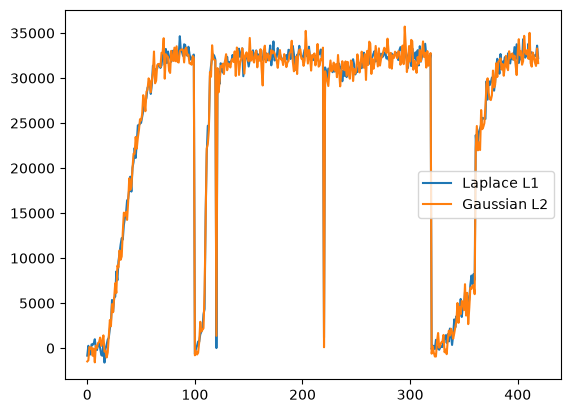

In [6]:
def dp_multi_cdf_laplace(epsilon):
    sens = (100 / 1) + (20 / 1) + (100000 / 1000) + (5000/50) + (100/1)
    return laplace_mech_vec(multi_cdf(), sensitivity=sens, epsilon=epsilon)

def dp_multi_cdf_gauss(epsilon, delta):
    sens = np.sqrt((100 / 1)**2 + (20 / 1)**2 + (100000 / 1000)**2 + (5000/50)**2 + (100/1)**2)
    return gaussian_mech_vec(multi_cdf(), sensitivity=sens, epsilon=epsilon, delta=delta)

plt.plot(dp_multi_cdf_laplace(1.0), label='Laplace L1');
plt.plot(dp_multi_cdf_gauss(1.0, 1e-5), label='Gaussian L2');
plt.legend();

## Question 5 (10 points)

Using the 3-point structure described in lecture, argue that `dp_multi_cdf_laplace` satisfies $\epsilon$-differential privacy and `dp_multi_cdf_gauss` satisfies $(\epsilon, \delta)$-differential privacy. Be precise about sensitivity.

### Sensitivity: 
For each CDF, a person could possibly appear in every group (e.g. someone who is 100 is atleast 1, 2, etc), so the sensitivity for each person is (upper bound) / (step size).

1st CDF (Age): each person contributes 100 / 1 = 100 sensitivity

2nd CDF (Education): each person contributes 20 / 1 = 20 sensitivity

3rd CDF (Capital Gain): each person contributes 100000 / 1000 = 100 sensitivity

4th CDF (Capital Loss): each person contributes 5000 / 50 = 100 sensitivity

5th CDF (Hours per week): each person contributes 100 / 1 = 100 sensitivity

#### dp_multi_cdf_laplace:
By the L1 sensitivity rule, the total sensitivity is 100 + 20 + 100 + 100 + 100 = 420

#### dp_multi_cdf_gauss:
By the L2 sensitivity rule, the total sensitivity is sqrt(100^2 + 20^2 + 100^2 + 100^2 + 100^2) ~= 201

### Composition:
#### dp_multi_cdf_laplace:
A budget of epsilon is passed into laplace_mech_vec where a qeury with epsilon is applied to each element in the vector. Items in the subset of independent of eachother. 

#### dp_multi_cdf_gauss
A budget of epsilon is passed into gaussian_mech_vec where a qeury with epsilon is applied to each element in the vector. Items in the subset of independent of eachother. 

### Post Processing:


## Question 6 (5 points)

Consider the code below, which graphs the total privacy cost of an averaging attack under (1) sequential composition and (2) advanced composition, for values of `k` between 1 and 200.

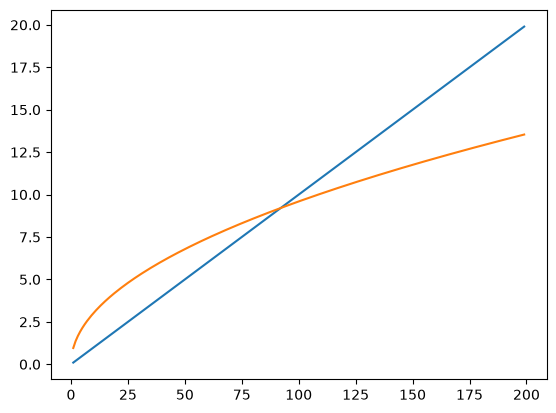

In [7]:
epsilon = .1
delta_p = 1e-5

def query():
    return len(adult[adult['Marital Status'] == 'Divorced'])

def avg_attack(k):
    return np.mean([laplace_mech(query(), 1, epsilon) for i in range(k)])
    
xs = range(1, 200)
privacy_cost_sequential = [k * epsilon for k in xs]
privacy_cost_advanced = [2 * epsilon * np.sqrt(2 * k * np.log(1/delta_p)) for k in xs]

plt.plot(xs, privacy_cost_sequential);
plt.plot(xs, privacy_cost_advanced);

In 2-5 sentences, answer the following:
- At approximately what point do the lines representing the two approaches cross? What does this mean about **which** composition technique should be used for an iterative algorithm?
- The two lines represent **different** privacy costs for the **same** algorithm. How can both be correct?


different algorithms can give different privacy costs because the cost they give is an an upper bound. e.g. x < 2 < 3 so x is bound by both 2 and 3.    